<a href="https://colab.research.google.com/github/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA/blob/main/notebooks/20_fuego/24_fuego_quema_celda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 24 · Fracción quemada por celda de 2 km (MapBiomas Fuego, 2015–2025)

**Autor:** Jonatan

**Pregunta:** ¿qué parte de cada celda de la grilla común se quema en un año? Es la capa de área quemada de la tabla de celdas (sección 14.4 de la ruta de trabajo).

**Entradas:**
- `modulos/fuego_expansion/datos/crudos/mapbiomas_fire_<municipio>_tiff/` (DVC): mapas anuales de área quemada de MapBiomas Fuego para los siete municipios. Son datos crudos.
- `datos/comunes/grilla_2km.gpkg` (cuaderno 02, DVC) y `datos/comunes/altillanura_municipios.gpkg` (cuaderno 01, DVC).
- `modulos/fuego_expansion/datos/crudos/mapbiomas_fuego/` (DVC): estadísticas municipales de área quemada, solo para el control.

**Salidas:**
- `datos/comunes/quema_celda.csv` y `datos/comunes/quema_celda_anual.csv` (DVC).
- `modulos/fuego_expansion/resultados/tablas/celda/quema_mapas_vs_estadisticas.csv`.
- `modulos/fuego_expansion/resultados/figuras/celda/quema_media_anual_celda.png`.

**Método:** cada píxel de unos 30 m se asigna por su centro a una celda de la grilla común (EPSG:9377) y solo cuenta si cae dentro del límite de su municipio. La fracción quemada de una celda en un año es el área de sus píxeles quemados sobre el área de todos sus píxeles. El cálculo está en `scripts/07_quema_celda.py`.

**Periodo:** 2015–2025, el único con mapas de fuego en los siete municipios. Cumaribo tiene mapas desde 2000, pero se recorta a la misma ventana para que todas las celdas midan lo mismo.

## 1. Preparar el entorno

Se bajan de DVC los mapas de fuego, la grilla y los límites municipales, y se cargan las funciones del módulo.

In [1]:
from importlib import import_module
import sqlite3
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Rutas del proyecto: funcionan en Colab y en local
import os, subprocess
EN_COLAB = 'google.colab' in sys.modules
REPO = 'https://github.com/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA.git'

if EN_COLAB:
    RAIZ = '/content/Proyecto-ALTILLANURA'
    if not os.path.exists(RAIZ):
        subprocess.run(['git', 'clone', '-q', REPO, RAIZ], check=True)
else:
    RAIZ = os.path.abspath(os.path.join('..', '..'))   # el cuaderno está en notebooks/<etapa>/

def traer(ruta):
    """Baja de DVC una carpeta o un archivo pesado del repo si todavía no está."""
    if os.path.exists(os.path.join(RAIZ, ruta)):
        return
    if EN_COLAB:
        from google.colab import auth
        auth.authenticate_user()
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'dvc[gs]'], check=True)
    subprocess.run([sys.executable, '-m', 'dvc', 'pull', '-q', ruta], cwd=RAIZ, check=True)
    print('Bajado de DVC:', ruta)

for ruta in ('modulos/fuego_expansion/datos/crudos', 'datos/comunes/grilla_2km.gpkg',
             'datos/comunes/altillanura_municipios.gpkg'):
    traer(ruta)
sys.path.insert(0, os.path.join(RAIZ, 'modulos', 'fuego_expansion', 'scripts'))
import config as cfg
from utils import estilo_matplotlib, pie_fuente

quema = import_module("07_quema_celda")
tablas = cfg.TABLAS / "celda"
figuras = cfg.FIGURAS / "celda"
for carpeta in (tablas, figuras):
    carpeta.mkdir(parents=True, exist_ok=True)
estilo_matplotlib()
print(f"Periodo: {quema.ANIOS[0]}–{quema.ANIOS[-1]} ({len(quema.ANIOS)} años)")

Periodo: 2015–2025 (11 años)


## 2. Fracción quemada por celda

Para cada municipio se leen sus once mapas por bloques. Un píxel cuenta como quemado en un año si su valor es mayor que 0. Las celdas del límite entre dos municipios reciben píxeles de los dos mapas; como cada mapa solo aporta los píxeles de su propio municipio, ninguno se cuenta dos veces.

La tabla resumen tiene tres medidas por celda: la fracción quemada en un año promedio, la fracción quemada al menos una vez en el periodo y el número de años con alguna quema.

In [2]:
resumen, anual, control = quema.construir()

con_pixeles = resumen["n_pixeles"] > 0
print(f"Celdas de la grilla común: {len(resumen):,} | sin píxeles: {(~con_pixeles).sum():,}")
print(f"Celdas con alguna quema en el periodo: {(resumen['quema_alguna_vez_pct'] > 0).sum():,} "
      f"({(resumen.loc[con_pixeles, 'quema_alguna_vez_pct'] > 0).mean():.1%})")
display(resumen[["quema_media_anual_pct", "quema_alguna_vez_pct", "anios_con_quema"]]
        .astype(float).describe().round(2))
por_municipio = (resumen.groupby("mpio_cdpmp")
                 .agg(celdas=("id_celda", "size"),
                      quema_media_anual_pct=("quema_media_anual_pct", "mean"),
                      quema_alguna_vez_pct=("quema_alguna_vez_pct", "mean"))
                 .rename(index=lambda c: cfg.NOMBRE[int(c)]))
display(por_municipio.round(2))

Celdas de la grilla común: 34,763 | sin píxeles: 7
Celdas con alguna quema en el periodo: 25,660 (73.8%)


,quema_media_anual_pct,quema_alguna_vez_pct,anios_con_quema
count,34756.00,34756.00,34756.00
mean,12.36,41.17,6.59
std,14.26,37.03,4.61
min,0.00,0.00,0.00
25%,0.00,0.00,0.00
50%,6.90,38.79,9.00
75%,21.31,77.77,11.00
max,89.37,100.00,11.00


,celdas,quema_media_anual_pct,quema_alguna_vez_pct
mpio_cdpmp,,,
Mapiripán,3129,7.41,28.10
Puerto Gaitán,4394,18.61,57.25
Puerto López,1847,6.20,27.91
Puerto Carreño,3121,19.04,61.68
La Primavera,4718,21.10,69.25
Santa Rosalía,940,22.56,68.70
Cumaribo,16614,8.01,27.48


### Lectura

De las **34.763 celdas** de la grilla, **7** quedan vacías porque son recortes del borde sin ningún centro de píxel. El **73,8 %** de las celdas tuvo alguna quema entre 2015 y 2025. La celda mediana quema el **6,9 %** de su área al año y la media es **12,4 %**. La quema es recurrente: la mitad de las celdas se quemó en **9 o más** de los 11 años y una cuarta parte en los 11, mientras que otra cuarta parte no registró quema.

Por municipio, el promedio de las celdas separa dos grupos. Santa Rosalía (**22,6 %**), La Primavera (**21,1 %**), Puerto Carreño (**19,0 %**) y Puerto Gaitán (**18,6 %**) queman cerca de una quinta parte de cada celda al año. Cumaribo (**8,0 %**), Mapiripán (**7,4 %**) y Puerto López (**6,2 %**) queman menos de una décima parte. Son promedios de celdas, no fracciones del área municipal.

## 3. Control: los mapas frente a las estadísticas de la plataforma

El área quemada que suman los mapas de cada municipio y año se compara con la de los CSV de estadísticas de MapBiomas Fuego, que son la fuente del panel municipal. Una razón cercana a 1 indica que los mapas son la misma colección, que el valor mayor que 0 sí significa quemado y que los CSV están en hectáreas. Las diferencias pequeñas son esperables porque los mapas se recortan con los límites del DANE (MGN 2025) y la plataforma usa los suyos.

In [3]:
preparar = import_module("01_preparar_panel")
estadisticas = preparar.fuego_mapbiomas()[["cod_mun", "anio", "quem_total_ha"]]
estadisticas["mpio_cdpmp"] = estadisticas["cod_mun"].map("{:05d}".format)
comparacion = control.merge(
    estadisticas.rename(columns={"quem_total_ha": "quemada_estadisticas_ha"})[
        ["mpio_cdpmp", "anio", "quemada_estadisticas_ha"]],
    on=["mpio_cdpmp", "anio"], how="left", validate="one_to_one")
comparacion["razon_mapas_estadisticas"] = (
    comparacion["quemada_mapas_ha"] / comparacion["quemada_estadisticas_ha"])
comparacion.to_csv(tablas / "quema_mapas_vs_estadisticas.csv", index=False, encoding="utf-8-sig")

display(comparacion.pivot(index="anio", columns="municipio", values="razon_mapas_estadisticas").round(3))
total = comparacion.groupby("municipio")[["quemada_mapas_ha", "quemada_estadisticas_ha"]].sum()
total["razon_mapas_estadisticas"] = total["quemada_mapas_ha"] / total["quemada_estadisticas_ha"]
display(total.round(3))

municipio,Cumaribo,La Primavera,Mapiripán,Puerto Carreño,Puerto Gaitán,Puerto López,Santa Rosalía
anio,,,,,,,
2015,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2016,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2017,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2018,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2019,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2020,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2021,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2022,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2023,1.0,1.0,1.0,1.0,1.0,1.0,1.0


,quemada_mapas_ha,quemada_estadisticas_ha,razon_mapas_estadisticas
municipio,,,
Cumaribo,5856133.579,5856133.667,1.0
La Primavera,4358381.950,4358314.904,1.0
Mapiripán,996847.073,996847.263,1.0
Puerto Carreño,2608799.493,2609063.334,1.0
Puerto Gaitán,3573172.491,3573209.192,1.0
Puerto López,483990.077,483990.879,1.0
Santa Rosalía,939641.880,939856.572,1.0


### Lectura del control

La razón entre el área quemada de los mapas y la de las estadísticas es **1,000** en los siete municipios y los once años. En el total del periodo la mayor diferencia es del **0,03 %** (Santa Rosalía). Los mapas son entonces la misma colección que las estadísticas del panel municipal, el valor mayor que 0 identifica el píxel quemado y los CSV están en hectáreas.

## 4. Mapa de la fracción quemada

Cada punto es una celda de 2 km en su centroide. La escala de color se corta en el percentil 99 para que unas pocas celdas muy quemadas no aplanen el resto.

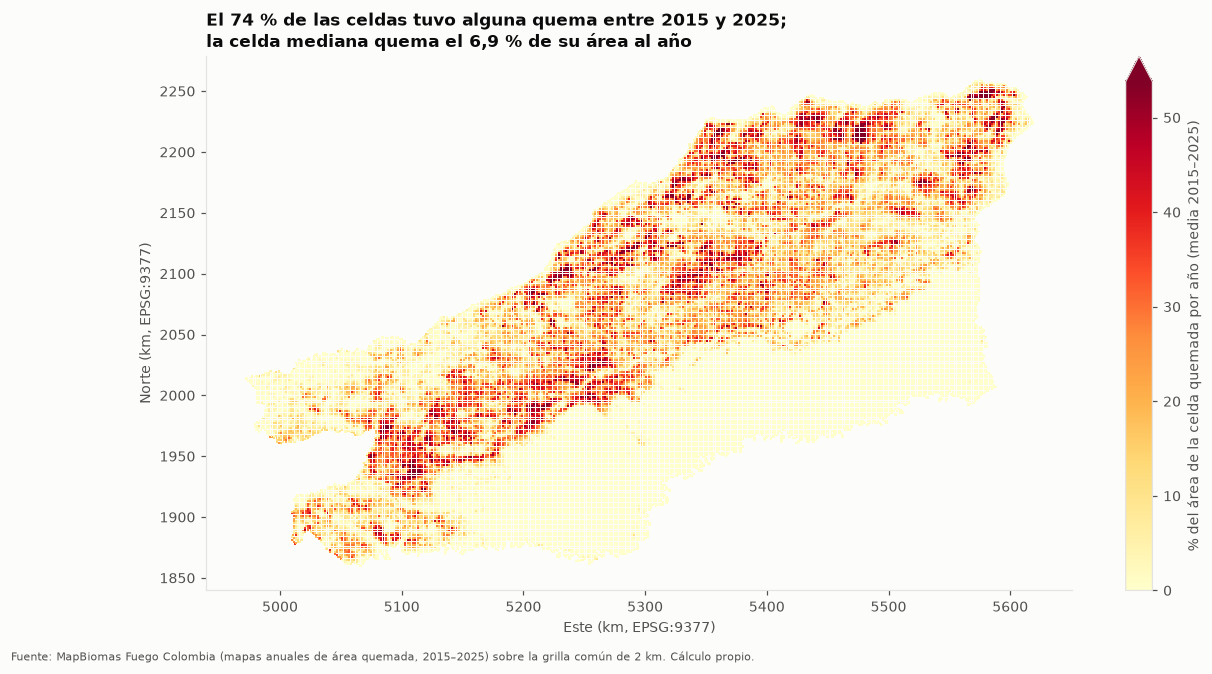

In [6]:
with sqlite3.connect(cfg.COMUNES / "grilla_2km.gpkg") as con:
    centros = pd.read_sql("SELECT id_celda, x_9377, y_9377 FROM grilla", con)
con.close()
mapa = resumen.merge(centros, on="id_celda", validate="one_to_one").dropna(subset="quema_media_anual_pct")

alguna = (mapa["quema_alguna_vez_pct"] > 0).mean() * 100
mediana = mapa["quema_media_anual_pct"].median()
fig, ax = plt.subplots(figsize=(11, 6), layout="constrained")
puntos = ax.scatter(mapa["x_9377"] / 1000, mapa["y_9377"] / 1000, c=mapa["quema_media_anual_pct"],
                    s=1.6, marker="s", linewidths=0, cmap="YlOrRd",
                    vmin=0, vmax=mapa["quema_media_anual_pct"].quantile(0.99))
fig.colorbar(puntos, ax=ax, label="% del área de la celda quemada por año (media 2015–2025)", extend="max")
titulo = (f"El {alguna:.0f} % de las celdas tuvo alguna quema entre 2015 y 2025;\n"
          f"la celda mediana quema el {mediana:.1f} % de su área al año").replace(".", ",")
ax.set(title=titulo, xlabel="Este (km, EPSG:9377)", ylabel="Norte (km, EPSG:9377)", aspect="equal")
ax.grid(False)
fig.get_layout_engine().set(rect=(0, 0.04, 1, 0.96))
pie_fuente(fig, "Fuente: MapBiomas Fuego Colombia (mapas anuales de área quemada, 2015–2025) sobre la grilla común de 2 km. Cálculo propio.")
fig.savefig(figuras / "quema_media_anual_celda.png")
plt.show()

## 5. Verificar y guardar

Antes de guardar se comprueba que hay una fila por celda de la grilla, que `id_celda` no se repite y que las fracciones están entre 0 y 100 %. Las dos tablas van a `datos/comunes/` y se versionan con DVC.

In [5]:
with sqlite3.connect(cfg.COMUNES / "grilla_2km.gpkg") as con:
    n_grilla = con.execute("SELECT COUNT(*) FROM grilla").fetchone()[0]
con.close()

assert len(resumen) == n_grilla and resumen["id_celda"].is_unique
assert resumen["mpio_cdpmp"].str.fullmatch(r"\d{5}").all()
assert len(anual) == len(resumen) * len(quema.ANIOS)
for serie in (resumen["quema_media_anual_pct"], resumen["quema_alguna_vez_pct"], anual["quema_pct"]):
    assert serie.dropna().between(0, 100 + 1e-9).all()
assert (resumen["quema_alguna_vez_pct"].dropna() + 1e-9 >= resumen["quema_media_anual_pct"].dropna()).all()

resumen.to_csv(cfg.COMUNES / "quema_celda.csv", index=False, float_format="%.4f")
anual.to_csv(cfg.COMUNES / "quema_celda_anual.csv", index=False, float_format="%.4f")
print(f"Guardado: quema_celda.csv ({len(resumen):,} filas) y quema_celda_anual.csv ({len(anual):,} filas)")
display(resumen.head())
print("Verificación OK")

Guardado: quema_celda.csv (34,763 filas) y quema_celda_anual.csv (382,393 filas)


,id_celda,mpio_cdpmp,n_pixeles,quema_media_anual_pct,quema_alguna_vez_pct,anios_con_quema
0,x4970_y2012,50573,166,0.000000,0.000000,0
1,x4970_y2014,50573,500,0.218181,2.399992,2
2,x4972_y2010,50573,214,0.000000,0.000000,0
3,x4972_y2012,50573,3400,0.000000,0.000000,0
4,x4972_y2014,50573,1782,0.178553,1.739614,3


Verificación OK
